## 5. P4: when are challenges most valuable?
Two kinds of value peak at different times. The option value of holding a challenge is highest early (panel a). The stakes of a flipped call are plausibly highest late. Here stakes rise from 1 in inning 1 to `m` in inning 9. **The multipliers are ASSUMED**.

In [ ]:
from abs_common import *          

 stakes_in_9th success_2left_inn1_3 success_2left_inn8_9  early_minus_late_pts  one_minus_two_left_inn8_9_pts share_challenges_inn7_9 value_share_inn1_3 value_share_inn7_9
           1.0                50.4%                45.4%                   5.0                            1.4                   31.7%              35.7%              30.1%
           1.5                52.2%                44.9%                   7.3                            2.1                   32.8%              29.9%              35.3%
           2.0                53.5%                45.1%                   8.5                            2.2                   33.8%              26.0%              39.4%
           3.0                56.1%                45.6%                  10.5                            1.7                   35.0%              21.2%              44.5%

Observed share of regulation challenges in innings 7-9: 37.9%


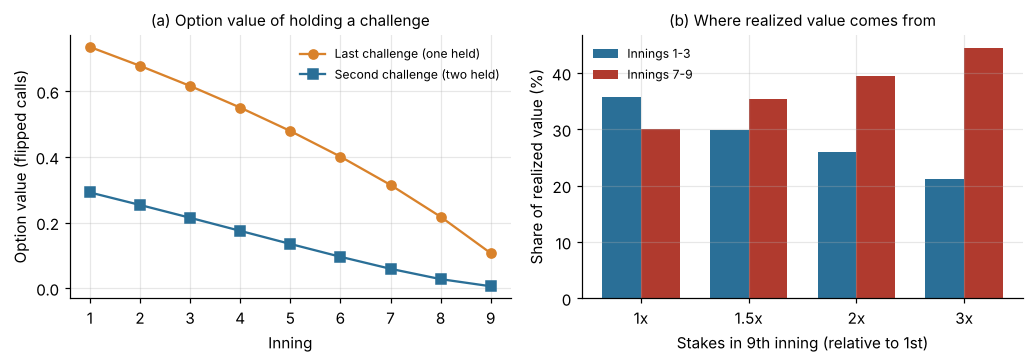

In [ ]:
STK = timing_run()             
rows = []
for m, s in STK.items():
    two = s["k"] == 2; val = s["ok"] * s["v"]
    e2 = s["ok"][two & (s["inn"] <= 3)].mean(); l2 = s["ok"][two & (s["inn"] >= 8)].mean()
    l1 = s["ok"][(s["k"] == 1) & (s["inn"] >= 8)].mean()
    rows.append(dict(stakes_in_9th=m, success_2left_inn1_3=pct(e2), success_2left_inn8_9=pct(l2),
                     early_minus_late_pts=round(100*(e2-l2), 1), one_minus_two_left_inn8_9_pts=round(100*(l1-l2), 1),
                     share_challenges_inn7_9=pct((s["inn"] >= 7).mean()),
                     value_share_inn1_3=pct(val[s["inn"] <= 3].sum()/val.sum()),
                     value_share_inn7_9=pct(val[s["inn"] >= 7].sum()/val.sum())))
stk = pd.DataFrame(rows)
print(stk.to_string(index=False))
share_obs = reg.loc[7:9][["n1","n2"]].sum().sum() / reg_chal
print(f"\nObserved share of regulation challenges in innings 7-9: {pct(share_obs)}")

fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.4))
ax[0].plot(range(1, 10), [D1[1, t] for t in start], "o-", color=ORANGE, label="Last challenge (one held)")
ax[0].plot(range(1, 10), [D1[2, t] for t in start], "s-", color=BLUE, label="Second challenge (two held)")
ax[0].set_xlabel("Inning"); ax[0].set_ylabel("Option value (flipped calls)"); ax[0].legend(frameon=False, fontsize=8)
ax[0].set_title("(a) Option value of holding a challenge", fontsize=10)
ms = list(STK); x = np.arange(len(ms))
e = [(STK[m]["ok"]*STK[m]["v"])[STK[m]["inn"] <= 3].sum() / (STK[m]["ok"]*STK[m]["v"]).sum() for m in ms]
l = [(STK[m]["ok"]*STK[m]["v"])[STK[m]["inn"] >= 7].sum() / (STK[m]["ok"]*STK[m]["v"]).sum() for m in ms]
ax[1].bar(x-.18, 100*np.array(e), .36, color=BLUE, label="Innings 1-3"); ax[1].bar(x+.18, 100*np.array(l), .36, color=RED, label="Innings 7-9")
ax[1].set_xticks(x); ax[1].set_xticklabels([f"{m:g}x" for m in ms]); ax[1].set_xlabel("Stakes in 9th inning (relative to 1st)")
ax[1].set_ylabel("Share of realized value (%)"); ax[1].legend(frameon=False, fontsize=8)
ax[1].set_title("(b) Where realized value comes from", fontsize=10)
plt.tight_layout()